# 03 — Neural Networks to Transformers: Architecture Showdown & INT8 Quantization Audit
Compares **TF-IDF + LogReg**, **MLP**, **1D-CNN (TextCNN)**, **BiLSTM (RNN)**, and **BERT-Tiny (FP32 vs. INT8 ONNX)** on CPU latency, artifact size, and quantization logit drift across 100 golden fixtures.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ARTIFACTS_DIR = Path.cwd().parents[1] / 'artifacts'
bench = pd.DataFrame(json.loads((ARTIFACTS_DIR / 'benchmark_summary.json').read_text()))
golden = json.loads((ARTIFACTS_DIR / 'golden_fixtures.json').read_text())

print(f"Schema Version: {golden['schema_version']} | Schema Hash: {golden['schema_hash']} | Golden Cases: {len(golden['cases'])}")
bench

Schema Version: v1.0.0 | Schema Hash: 8f761a46c23e | Golden Cases: 100


,model,seen_f1,unseen_f1,cpu_p50_ms,size_mb
0,TF-IDF + LogReg,1.0,0.3512,0.489,0.15
1,MLP (AvgPool),1.0,0.4137,0.028,7.47
2,1D-CNN (TextCNN),1.0,0.3778,0.126,7.60
3,BiLSTM (RNN),1.0,0.3141,0.424,7.71
4,BERT-Tiny (FP32 ONNX),1.0,0.5848,0.550,16.81
5,BERT-Tiny (INT8 ONNX),1.0,0.5848,0.688,4.31


In [2]:
# Audit FP32 vs. INT8 quantization drift across all 100 golden fixtures
max_logit_diffs = []
label_matches = 0
for c in golden['cases']:
    fp32 = np.array(c['fp32_logits'], dtype=np.float64)
    int8 = np.array(c['int8_logits'], dtype=np.float64)
    max_logit_diffs.append(float(np.max(np.abs(fp32 - int8))))
    if int(np.argmax(fp32)) == int(np.argmax(int8)):
        label_matches += 1

diffs = np.array(max_logit_diffs)
print(f'FP32 <-> INT8 Label Agreement: {label_matches}/{len(diffs)} ({label_matches/len(diffs):.1%})')
print(f'Max |FP32 - INT8| Logit Diff -> p50: {np.median(diffs):.4f} | p95: {np.percentile(diffs, 95):.4f} | max: {np.max(diffs):.4f}')

FP32 <-> INT8 Label Agreement: 100/100 (100.0%)
Max |FP32 - INT8| Logit Diff -> p50: 0.0426 | p95: 0.2542 | max: 0.2542


Saved chart to /home/gun/work/github.com/gunawanwijaya/apprentice/03-transformer-onnx/artifacts/transformer_benchmark_summary.png


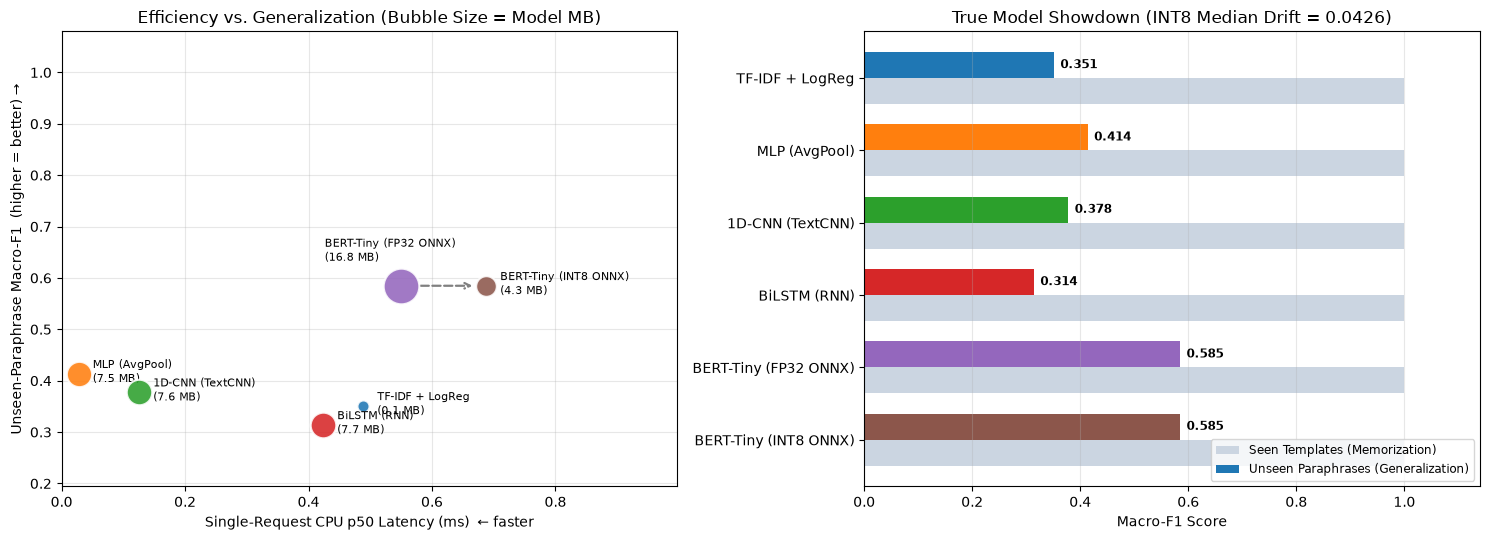

In [3]:
colors = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5']

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: Pareto Frontier — CPU Latency (x) vs. Unseen Macro-F1 (y), Bubble Size = Artifact MB
for i, row in bench.iterrows():
    bubble = row['size_mb'] * 35 + 70
    axes[0].scatter(
        row['cpu_p50_ms'],
        row['unseen_f1'],
        s=bubble,
        color=colors[i % len(colors)],
        alpha=0.88,
        edgecolors='white',
        linewidth=1.5,
        zorder=3,
    )
    offset = (-55, 18) if 'FP32' in row['model'] else (10, -6)
    axes[0].annotate(
        f"{row['model']}\n({row['size_mb']:.1f} MB)",
        (row['cpu_p50_ms'], row['unseen_f1']),
        textcoords='offset points',
        xytext=offset,
        fontsize=8.2,
    )

# Dashed compression arrow connecting BERT-Tiny FP32 -> INT8
fp32_row = bench[bench['model'].str.contains('FP32')].iloc[0]
int8_row = bench[bench['model'].str.contains('INT8')].iloc[0]
axes[0].annotate(
    '',
    xy=(int8_row['cpu_p50_ms'], int8_row['unseen_f1']),
    xytext=(fp32_row['cpu_p50_ms'], fp32_row['unseen_f1']),
    arrowprops=dict(arrowstyle='->', linestyle='--', color='gray', lw=1.6, shrinkA=14, shrinkB=10),
    zorder=2,
)
axes[0].set_title('Efficiency vs. Generalization (Bubble Size = Model MB)')
axes[0].set_xlabel('Single-Request CPU p50 Latency (ms)  ← faster')
axes[0].set_ylabel('Unseen-Paraphrase Macro-F1  (higher = better) →')
axes[0].set_xlim(0, bench['cpu_p50_ms'].max() * 1.45)
axes[0].set_ylim(max(0.0, bench['unseen_f1'].min() - 0.12), 1.08)
axes[0].grid(alpha=0.3)

# Right: True Model Showdown — Seen Templates (Memorization) vs. Unseen Paraphrases (Generalization)
y_pos = np.arange(len(bench))
h = 0.36
axes[1].barh(y_pos + h / 2, bench['seen_f1'], height=h, color='#cbd5e1', label='Seen Templates (Memorization)')
bars = axes[1].barh(y_pos - h / 2, bench['unseen_f1'], height=h, color=colors[:len(bench)], label='Unseen Paraphrases (Generalization)')

for bar, val in zip(bars, bench['unseen_f1']):
    axes[1].text(val + 0.012, bar.get_y() + bar.get_height() / 2, f'{val:.3f}', va='center', fontsize=8.5, fontweight='bold')

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(bench['model'])
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1.14)
axes[1].set_xlabel('Macro-F1 Score')
axes[1].set_title(f'True Model Showdown (INT8 Median Drift = {np.median(diffs):.4f})')
axes[1].legend(loc='lower right', fontsize=8.5)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
out_img = ARTIFACTS_DIR / 'transformer_benchmark_summary.png'
plt.savefig(out_img, dpi=150)
print(f'Saved chart to {out_img}')
plt.show()